# Fun with RF Pulses?

**Part:** J – Advanced & fun topics · **Reading time:** ~30 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Prerequisites:** [A2 Bloch equation](A2_Bloch_Equation.ipynb) (rotating frame, effective field), [E1 RF pulses](E1_RF_Pulses.ipynb) · **Refreshers you may want:** [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

Yes, you heard me right. Maybe it takes a special type of person, but RF pulses can be fun! This chapter collects a few beautiful examples: **adiabatic pulses** that work even when the RF amplitude is wrong, "pretty pictures" of magnetization under long hard pulses, and **composite pulses** that cancel their own errors.

*Movies in this chapter were created with SpinBench (https://heartvista.ai/spinbench) for the original book; every movie is accompanied by a Python simulation you can modify.*

**Why this chapter matters.** Beyond the fun, adiabatic and composite pulses solve a real engineering problem: the transmit field $B_1^+$ is never perfectly uniform. At 3 T, and even more at 7 T, the actual flip angle can vary by ±30 % or more across the body (see [B5](B5_RF_System_and_Receive_Chain.ipynb)). Pulses that tolerate this are essential for inversion recovery, fat suppression and spin echoes at high field.

## Learning goals

1. Have fun
2. *(added)* Explain adiabatic pulses with the **effective field** in a frequency-swept frame, and state the adiabatic condition.
3. *(added)* Show by simulation that a hyperbolic-secant inversion works over a wide range of $B_1$ amplitudes, unlike a hard 180° pulse.
4. *(added)* Explain why off-resonance changes the rotation of a hard pulse, and visualize it.
5. *(added)* Understand how a composite pulse (90°ₓ180°ᵧ90°ₓ) compensates flip-angle errors.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec M$, $M_z$ | magnetization; its longitudinal component | normalized ($M_0=1$) | $M_z=-1$ = perfect inversion |
| $b_1(t)=B_{1,x}+iB_{1,y}$ | complex RF envelope in the rotating frame | T | µT |
| $A(t)$, $A_0$ | RF amplitude envelope; its peak value | T | $A_0$ ≈ 10–20 µT |
| $\Delta\omega_{rf}(t)$ | instantaneous RF frequency offset (frequency sweep) | rad/s | ± a few kHz × 2π |
| $\phi_{rf}(t)$ | RF phase, $\phi_{rf}(t)=\int_0^t\Delta\omega_{rf}\,d\tau$ | rad | |
| $\Delta\omega$, $\Delta f$ | spin off-resonance (angular / in Hz) | rad/s, Hz | |
| $\vec B_{eff}$ | effective field in the frame rotating with the RF | T | |
| $\alpha_{eff}$ | angle of $\vec B_{eff}$ from the z-axis | rad | sweeps 0 → π |
| $\kappa$ | hyperbolic-secant sweep rate parameter (books often call it β: clash with Cayley–Klein β) | s⁻¹ | 800 s⁻¹ |
| $\mu$ | hyperbolic-secant sweep-width parameter | – | 5 |
| $\mathrm{sech}(x)=1/\cosh(x)$ | hyperbolic secant | – | |
| $T_{rf}$ | pulse duration | s | 1–10 ms |
| $s_{B1}$ | $B_1$ scale factor: actual / nominal RF amplitude | – | 0.5–2 |
| $\theta$ | flip angle | rad | |
| $\gamma,\bar\gamma$ | gyromagnetic ratio (angular / Hz) | rad s⁻¹T⁻¹, Hz/T | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Adiabatic pulses

Adiabatic pulses are a class of pulses that are essentially **insensitive to $B_1^+(\vec r)$ field inhomogeneities**. In other words, they perform the same even if the amplitude of the magnetic field created by the RF transmit coil varies.

They are mostly used for 180° flip angles, for inversion or spin echoes. Typically **two** adiabatic 180° pulses are required when used for refocusing, to cancel unwanted phase.

### 1.1 The idea: drag the magnetization along with the effective field

Instead of a fixed frequency, an adiabatic pulse **sweeps its frequency** through resonance. Go into a frame that rotates *with the RF* (not just at the Larmor frequency). In that frame the RF is a fixed vector along x, and the spins see an effective field (compare the off-resonance discussion in [A2](A2_Bloch_Equation.ipynb)):

$$\vec B_{eff}(t) = \begin{bmatrix} A(t) \\ 0 \\ \dfrac{\Delta\omega - \Delta\omega_{rf}(t)}{\gamma}\end{bmatrix}$$

where $A(t)$ is the RF amplitude, $\Delta\omega$ the spin's off-resonance and $\Delta\omega_{rf}(t)$ the RF frequency offset at time $t$.

**In words:** at the start the RF is far off resonance, so $\vec B_{eff}$ points (almost) along $+z$, parallel to $\vec M$. As the frequency sweeps through resonance, $\vec B_{eff}$ tilts through the transverse plane, and at the end it points along $-z$.

If $\vec B_{eff}$ turns **slowly** compared with how fast $\vec M$ precesses around it, then $\vec M$ simply follows, like a spinning top following a slowly tilted axis. This is the **adiabatic condition**:

$$\left|\frac{d\alpha_{eff}}{dt}\right| \ll \gamma\,|\vec B_{eff}|$$

where $\alpha_{eff}$ is the angle of $\vec B_{eff}$ from the z-axis. As long as it holds, the final state does not depend on the exact RF amplitude. A stronger $B_1$ only makes the condition *better* satisfied. That is the source of the $B_1$ insensitivity.

### 1.2 The hyperbolic-secant (HS) pulse

The most famous adiabatic inversion pulse (Silver, Joseph & Hoult 1984) uses

$$A(t) = A_0\,\mathrm{sech}(\kappa t), \qquad \Delta\omega_{rf}(t) = \mu\kappa\tanh(\kappa t), \qquad -\tfrac{T_{rf}}{2}\le t\le \tfrac{T_{rf}}{2}$$

where $A_0$ is the peak amplitude, $\kappa$ sets the sweep rate and $\mu$ the sweep width. The frequency sweeps over $\pm\mu\kappa$, so the inversion bandwidth is about $\mu\kappa/\pi$ Hz (the sweep direction does not matter; sweeping the other way also inverts). In the rotating frame we implement the frequency sweep as a phase ramp, $b_1(t) = A(t)\,e^{-i\phi_{rf}(t)}$ with $\phi_{rf}(t) = \int\Delta\omega_{rf}\,d\tau$. The minus sign makes the RF rotate *clockwise*, in the same sense as the spins precess in our convention ($e^{-i\omega t}$), so that a positive $\Delta\omega_{rf}$ really means "RF frequency above the rotating frame".

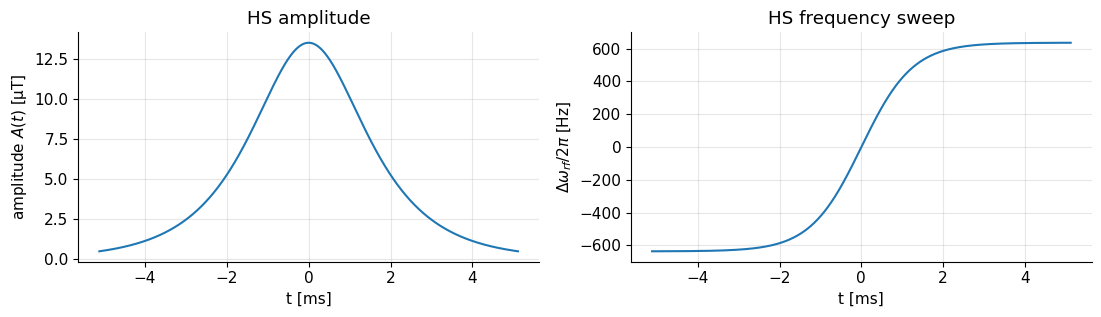

inversion bandwidth ~ mu*kappa/pi = 1273 Hz; adiabatic threshold ~ sqrt(mu)*kappa/gamma = 6.7 uT (we use A0 = 13.5 uT)


In [2]:
# Hyperbolic-secant inversion pulse
T_rf, dt = 10.24e-3, 10e-6
kappa, mu, A0 = 800.0, 5.0, 13.5e-6          # 1/s, -, T
t = (np.arange(int(round(T_rf / dt))) + 0.5) * dt - T_rf / 2
A = A0 / np.cosh(kappa * t)
dw_rf = mu * kappa * np.tanh(kappa * t)      # rad/s
phi_rf = np.cumsum(dw_rf) * dt
b1_hs = A * np.exp(-1j * phi_rf)             # clockwise-rotating RF (same sense as precession)

# Reference: hard 180 deg pulse of 1 ms
T_hard = 1e-3
b1_hard = np.full(int(round(T_hard / dt)), mt.b1_for_flip(np.pi, T_hard), complex)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(t * 1e3, A * 1e6); ax[0].set_ylabel("amplitude $A(t)$ [µT]"); ax[0].set_xlabel("t [ms]"); ax[0].set_title("HS amplitude")
ax[1].plot(t * 1e3, dw_rf / (2 * np.pi)); ax[1].set_ylabel(r"$\Delta\omega_{rf}/2\pi$ [Hz]"); ax[1].set_xlabel("t [ms]")
ax[1].set_title("HS frequency sweep"); plt.tight_layout(); plt.show()
print(f"inversion bandwidth ~ mu*kappa/pi = {mu*kappa/np.pi:.0f} Hz; adiabatic threshold ~ sqrt(mu)*kappa/gamma = "
      f"{np.sqrt(mu)*kappa/mt.GAMMA*1e6:.1f} uT (we use A0 = {A0*1e6:.1f} uT)")

### 1.3 Watch the magnetization follow $\vec B_{eff}$

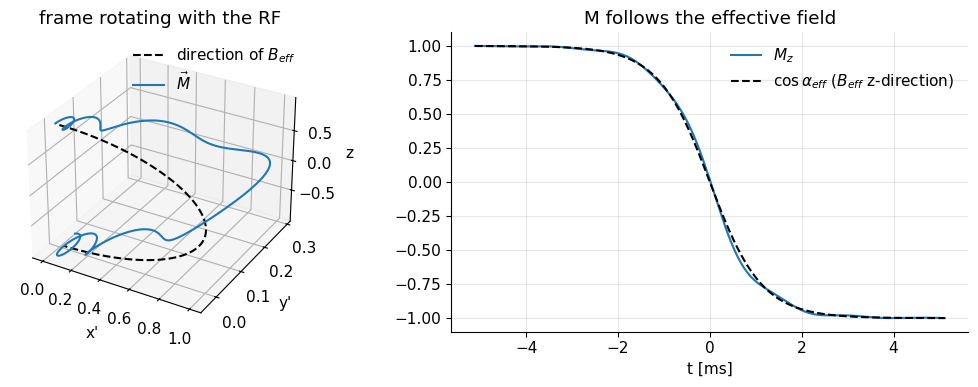

final Mz = -0.9987


In [3]:
_, M = mt.bloch_simulate(B1=b1_hs, dt=dt, M_init=[0, 0, 1])
M = M[:, 0, :]
# direction of B_eff in the frame rotating with the RF (on resonance: dw = 0)
Beff = np.stack([A, np.zeros_like(A), -dw_rf / mt.GAMMA], axis=-1)
Beff_dir = Beff / np.linalg.norm(Beff, axis=-1, keepdims=True)
# M expressed in the same RF-following frame (undo the RF phase)
Mxy_rf = (M[1:, 0] + 1j * M[1:, 1]) * np.exp(1j * phi_rf)

fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(Beff_dir[:, 0], Beff_dir[:, 1], Beff_dir[:, 2], "k--", label=r"direction of $B_{eff}$")
ax.plot(Mxy_rf.real, Mxy_rf.imag, M[1:, 2], "C0", label=r"$\vec M$")
ax.set_xlabel("x'"); ax.set_ylabel("y'"); ax.set_zlabel("z"); ax.legend(); ax.set_title("frame rotating with the RF")
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t * 1e3, M[1:, 2], label="$M_z$"); ax2.plot(t * 1e3, Beff_dir[:, 2], "k--", label=r"$\cos\alpha_{eff}$ ($B_{eff}$ z-direction)")
ax2.set_xlabel("t [ms]"); ax2.legend(); ax2.set_title("M follows the effective field"); plt.tight_layout(); plt.show()
print(f"final Mz = {M[-1, 2]:.4f}")

**Interpretation.** In the frame that rotates with the RF, $\vec B_{eff}$ (dashed) tilts smoothly from $+z$ to $-z$ through the transverse plane, and $\vec M$ follows it closely, ending almost perfectly inverted. The small wiggles are $\vec M$ precessing around $\vec B_{eff}$ while following it.

### 1.4 The payoff: insensitivity to $B_1$ amplitude

Now scale the RF amplitude by a factor $s_{B1}$ (as happens in a real body with an imperfect transmit field) and compare the HS pulse with a hard 180° pulse.

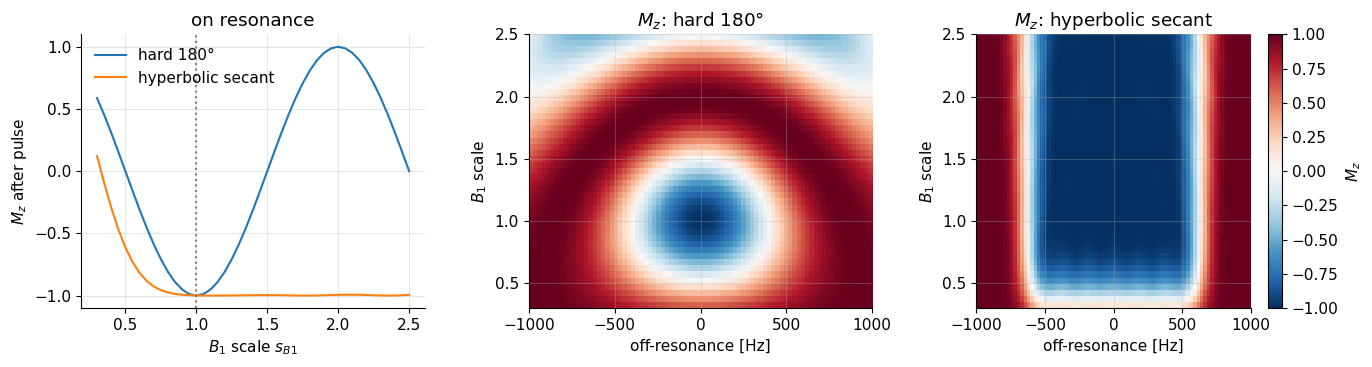

In [4]:
scales = np.linspace(0.3, 2.5, 45)
df = np.linspace(-1000, 1000, 81)
Mz_hs = np.zeros((len(scales), len(df))); Mz_hard = np.zeros_like(Mz_hs)
for i, s in enumerate(scales):
    Mz_hs[i] = mt.bloch_simulate(B1=s * b1_hs, dt=dt, df=df, return_all=False)[1][:, 2]
    Mz_hard[i] = mt.bloch_simulate(B1=s * b1_hard, dt=dt, df=df, return_all=False)[1][:, 2]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
i0 = np.argmin(np.abs(df))
ax[0].plot(scales, Mz_hard[:, i0], label="hard 180°")
ax[0].plot(scales, Mz_hs[:, i0], label="hyperbolic secant")
ax[0].axvline(1, color="gray", ls=":"); ax[0].set_xlabel("$B_1$ scale $s_{B1}$"); ax[0].set_ylabel("$M_z$ after pulse")
ax[0].set_title("on resonance"); ax[0].legend()
for a_, Mz, name in ((ax[1], Mz_hard, "hard 180°"), (ax[2], Mz_hs, "hyperbolic secant")):
    im = a_.imshow(Mz, origin="lower", aspect="auto", extent=[df[0], df[-1], scales[0], scales[-1]], cmap="RdBu_r", vmin=-1, vmax=1)
    a_.set_xlabel("off-resonance [Hz]"); a_.set_ylabel("$B_1$ scale"); a_.set_title(f"$M_z$: {name}")
plt.colorbar(im, ax=ax[2], label="$M_z$"); plt.tight_layout(); plt.show()

**Interpretation.** The hard pulse inverts perfectly only at exactly the right amplitude ($s_{B1}=1$); at 70 % amplitude it only reaches $M_z\approx-0.6$ instead of $-1$, and at 50 % it merely saturates ($M_z\approx 0$). The HS pulse inverts almost perfectly (blue) for **any amplitude above the adiabatic threshold** and over a ±600 Hz band of off-resonance. The price: a longer pulse (10 ms vs 1 ms) and more RF energy (SAR, see [B6](B6_MRI_Safety.ipynb)).

The movie below (from the original book) shows two adiabatic 180° inversions. The pulses "sweep" the magnetization from the $+z$ axis to the $-z$ axis, and back again with the second pulse:

![adiabatic_gif.gif](../images/adiabatic_gif.gif)

*Yellow: $B_1$ (RF) vector. White: net magnetizations for a range of frequencies around the Larmor frequency. The amplitude of the adiabatic pulses is plotted in the bottom left corner.*

> **🔧 Engineering reality:** Adiabatic inversion pulses are standard for inversion recovery at 3 T and 7 T (e.g. MPRAGE, FLAIR) and for fat suppression (SPAIR). Adiabatic *excitation* (BIR-4) and *refocusing* (pairs of HS pulses) also exist, but they are long and SAR-hungry, so they are used where $B_1$ robustness matters most.

## 2. Pretty pictures: a long hard pulse and many off-resonances

The original book shows two movies in which a continuous RF pulse (constant amplitude, "hard" pulse) is applied to spins over a range of off-resonance frequencies around the Larmor frequency. Off-resonance changes the **axis and rate** of rotation: each spin rotates about its own effective field $\vec B_{eff} = [B_1, 0, \Delta\omega/\gamma]$, which is tilted out of the transverse plane by the off-resonance. One movie applies the RF along x, the other along y.

![bigtip_gif.gif](../images/bigtip_gif.gif)

![bigtipy_gif.gif](../images/bigtipy_gif.gif)

The Python version: we snapshot the "string" of magnetization vectors (one per off-resonance frequency) at a few moments during a long RF pulse along x.

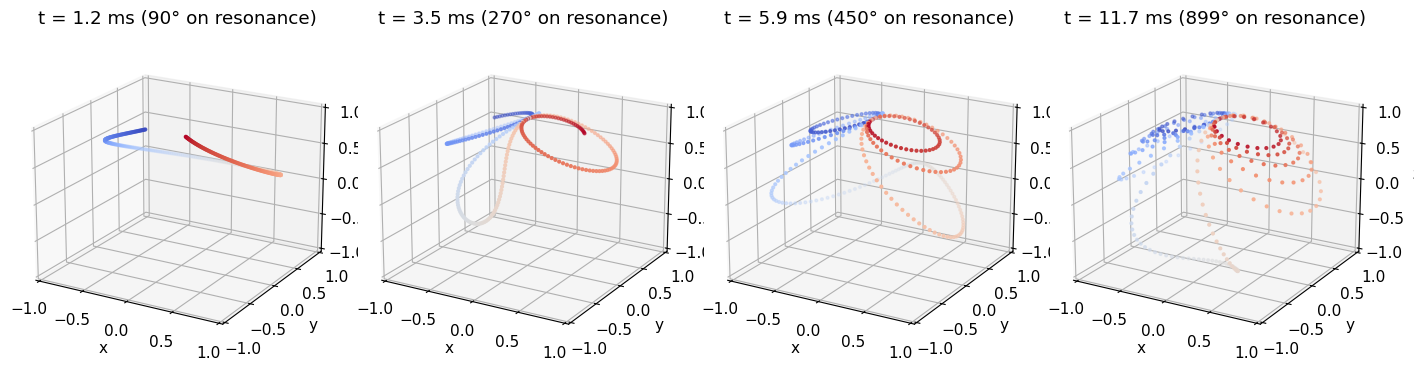

largest tip angle ever reached by the spins at +-3 f1 off-resonance: 38 deg (prediction 2*atan(1/3) = 37 deg)


In [5]:
B1_amp = 5e-6                              # T, constant RF along x
f1 = mt.GAMMA_BAR * B1_amp                 # nutation frequency on resonance [Hz]
df_s = np.linspace(-3 * f1, 3 * f1, 301)   # off-resonances [Hz]
n = 1000; dt_s = 1 / f1 / 400              # simulate 2.5 nutation periods on resonance
tt, Ms = mt.bloch_simulate(B1=np.full(n, B1_amp, complex), dt=dt_s, df=df_s)

snap = [100, 300, 500, 999]
fig = plt.figure(figsize=(14, 3.8))
for j, k in enumerate(snap):
    ax = fig.add_subplot(1, len(snap), j + 1, projection="3d")
    P = Ms[k]
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=df_s, cmap="coolwarm", s=4)
    ax.view_init(elev=20, azim=-60)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_title(f"t = {tt[k]*1e3:.1f} ms ({tt[k]*f1*360:.0f}° on resonance)")
plt.tight_layout(); plt.show()
edge = np.abs(df_s) > 2.9 * f1
tip = np.degrees(np.arccos(np.clip(Ms[:, edge, 2], -1, 1))).max()
print(f"largest tip angle ever reached by the spins at +-3 f1 off-resonance: {tip:.0f} deg "
      f"(prediction 2*atan(1/3) = {2*np.degrees(np.arctan(1/3)):.0f} deg)")

**Interpretation.** On resonance (middle of the string) the magnetization nutates in the y–z plane exactly as a simple flip. Far off resonance (red/blue ends) the effective field is tilted toward z, so those spins trace cones around it and never tip by more than about $2\arctan(B_1\gamma/|\Delta\omega|)$ (≈37° for the ends of our string, as printed above). In between, they rotate faster (larger $|\vec B_{eff}|$) about tilted axes, so the string winds into a spiral that becomes more twisted the longer the pulse lasts. This is the full, non-linear picture behind the simple statement "a hard pulse has a sinc-shaped profile" (which only holds for small flip angles, see [E1](E1_RF_Pulses.ipynb)).

> **TODO (polish):** Add the same snapshot figure for RF along y (bigtipy) and an optional ipywidgets slider over time.

## 3. Bonus: composite pulses cancel their own errors

A different trick for $B_1$ robustness: replace one pulse by a short sequence of pulses with different phases, chosen so that errors cancel. The classic **composite inversion pulse** (Levitt & Freeman 1979) is

$$90^\circ_x\;180^\circ_y\;90^\circ_x$$

i.e. a 90° pulse about x, a 180° pulse about y, and another 90° about x. If every angle is scaled by the same error $s_{B1}$, the second-order errors of the three rotations largely compensate.

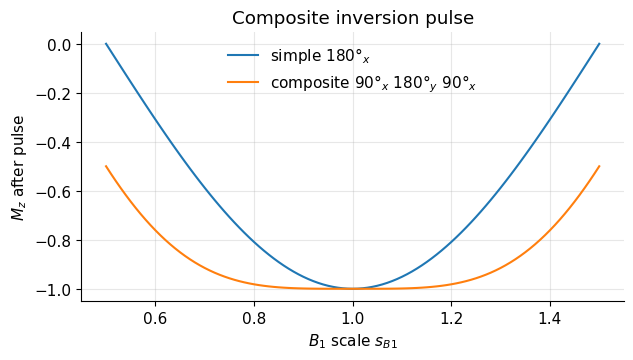

B1 scale 0.8: Mz simple = -0.809, composite = -0.982
B1 scale 1.2: Mz simple = -0.809, composite = -0.982


In [6]:
def hard(theta, phase_axis, T=0.25e-3):
    """Rectangular pulse of flip angle theta about axis at angle phase_axis in the x-y plane (0 = x, pi/2 = y)."""
    n = int(round(T / dt))
    return np.full(n, mt.b1_for_flip(theta, T) * np.exp(1j * phase_axis), complex)

b1_comp = np.concatenate([hard(np.pi / 2, 0), hard(np.pi, np.pi / 2, 0.5e-3), hard(np.pi / 2, 0)])
b1_180 = hard(np.pi, 0, 1e-3)
scales2 = np.linspace(0.5, 1.5, 101)
Mz_c = [mt.bloch_simulate(B1=s * b1_comp, dt=dt, return_all=False)[1][0, 2] for s in scales2]
Mz_s = [mt.bloch_simulate(B1=s * b1_180, dt=dt, return_all=False)[1][0, 2] for s in scales2]

plt.figure(figsize=(7, 3.5))
plt.plot(scales2, Mz_s, label="simple 180°$_x$")
plt.plot(scales2, Mz_c, label="composite 90°$_x$ 180°$_y$ 90°$_x$")
plt.xlabel("$B_1$ scale $s_{B1}$"); plt.ylabel("$M_z$ after pulse"); plt.legend(); plt.title("Composite inversion pulse")
plt.show()
for s in (0.8, 1.2):
    i = np.argmin(np.abs(scales2 - s))
    print(f"B1 scale {s}: Mz simple = {Mz_s[i]:+.3f}, composite = {Mz_c[i]:+.3f}")

**Interpretation.** With a 20 % amplitude error, the simple pulse leaves noticeably more residual $M_z$ than the composite pulse, whose curve is much flatter around $s_{B1}=1$. Composite pulses are short (unlike adiabatic pulses) but only compensate moderate errors. Both ideas, adiabatic and composite, are used in modern high-field MRI.

## Key takeaways

* In a frame that rotates **with a frequency-swept RF**, spins see an effective field $\vec B_{eff}$ that tilts from $+z$ to $-z$; if it turns slowly enough (**adiabatic condition**), $\vec M$ follows it.
* Above the adiabatic threshold, the result is **independent of the exact $B_1$ amplitude**: robust inversion despite transmit-field inhomogeneity.
* The hyperbolic-secant pulse inverts uniformly over a bandwidth $\approx\mu\kappa/\pi$, at the price of a longer pulse and more SAR.
* Off-resonance tilts the rotation axis of a hard pulse; for large flip angles the profile is far from the small-tip Fourier picture.
* **Composite pulses** (e.g. 90°ₓ180°ᵧ90°ₓ) compensate flip-angle errors with short pulse sequences.

## Check your understanding

1. Why does doubling the $B_1$ amplitude of an adiabatic pulse *not* ruin the inversion, while it would turn a hard 180° pulse into a 360° pulse?

<details><summary>Answer</summary>

The final state of an adiabatic pulse is set by where $\vec B_{eff}$ ends up (along $-z$), not by an accumulated rotation angle. A larger $B_1$ makes $|\vec B_{eff}|$ larger, so $\vec M$ precesses faster around it and follows it even better; the adiabatic condition is more strongly satisfied. A hard pulse's flip angle $\theta=\gamma B_1 T_{rf}$ scales directly with $B_1$: 2 × 180° = 360°, which leaves $M_z = +1$.

</details>

2. What limits how short you can make an adiabatic pulse?

<details><summary>Answer</summary>

The adiabatic condition $|d\alpha_{eff}/dt| \ll \gamma|\vec B_{eff}|$: a faster sweep needs a larger $B_1$. $B_1$ is limited by the RF amplifier's peak power and by SAR (which grows with $B_1^2$), so in practice adiabatic pulses last several milliseconds.

</details>

3. In the "pretty pictures" simulation, why are the spins far off resonance barely tipped?

<details><summary>Answer</summary>

Their effective field $\vec B_{eff}=[B_1,0,\Delta\omega/\gamma]$ points mostly along z because $|\Delta\omega/\gamma| \gg B_1$. Rotation about an axis close to z keeps $\vec M$ (which starts along z) near the north pole, so they only trace small cones.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Fun with RF Pulses?". Changes: every SpinBench movie complemented with a Python simulation; adiabatic theory (effective field, adiabatic condition, hyperbolic-secant pulse) and $B_1$-robustness maps added; composite-pulse section added; typos fixed ("inhomongeneities", "frequnecies").*